In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from coffea.processor import accumulate
import os
import re
import pandas as pd
import hist
import matplotlib as mpl
import mplhep
import sys
import hist
import hist.intervals


sys.path.append("/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/analysisTools")
import plotTools as ptools
import utils

In [2]:
f_sig = "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/VertexRes2026/VtxResdR_NOCUTS.coffea"

sig_histo = util.load(f_sig) [0]

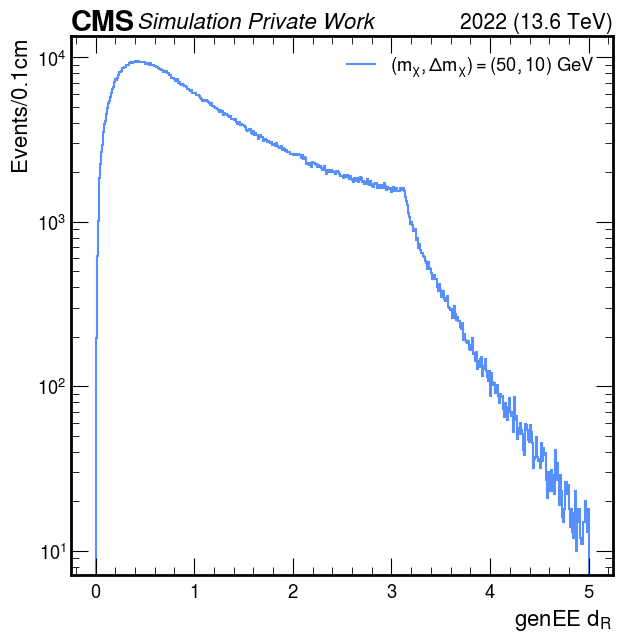

In [3]:
fig, ax = plt.subplots(figsize=(7,7))


# Plot settings
plot_dict = {
    'variable':'genEEdR',
    'cut': 'cut0',
    'year': 2022
}

style_dict = {
        'fig': fig,
        'ax': ax,
        'rebin': 1j,
        'xlim': [0,5],     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
        'doLogy': True, 
        'doLogx': False,
        'doDensity': False,
        'doYerr': False, 
        'xlabel': r"genEE $d_{R}$ ",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
        'ylabel': 'Events/0.1cm',   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
        'label': None,    # if None, the default will show up; otherwise give as a string, i.e. 'Highest ctau signal samples'
        'flow': None,     # overflow
        'doSave': False,
        'outDir': './plots/',
        'outName': f'background_cut7_Lxy_max10.png'
    }

#signal points
samples = {
    # 10: 
    # {
        
    #     0.2: [100],
    # },
    # 20: 
    # {
        
    #     0.2: [100],
        
    # },
    # 30: 
    # {
       
    #     0.2: [100]
    # },
    # 40: 
    # {
    #     0.2: [100],
    # },
    50:
    {
        
        0.2: [100],
    },
    # 60:
    # {
        
    #      0.1: [100],
    #      0.2: [100]
    
    # },
    # 70:
    # {    0.1: [100],
    #      0.2: [100],
    # },
    # 80:
    
    # {    0.1: [100],
    #      0.2: [100],
    # },
    # 90:
    # {    0.1: [100],
    #      0.2: [100],
    # },
    # 100:
    
    # {    0.1: [100],
    #      0.2: [100],
    # }
}


h_list_lpt_den=[]
h_sum_lpt_den = None


for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            h_lpt_den = ptools.plot_signal_1D(sig_histo, m1, delta, ctau, plot_dict, style_dict)
            

sum_counts_den= [[ 36254.  79211.  46212.  24170.  14167.]
 [ 67530. 134865.  74282.  38462.  22596.]
 [ 44196. 131590. 102030.  63557.  41823.]
 [ 15666.  54413.  52449.  39616.  29940.]]
sum_edges_pt_den= [  0.   5.  10.  20. 100.]
sum_edges_vxy_den= [ 0.  1.  5. 10. 15. 20.]


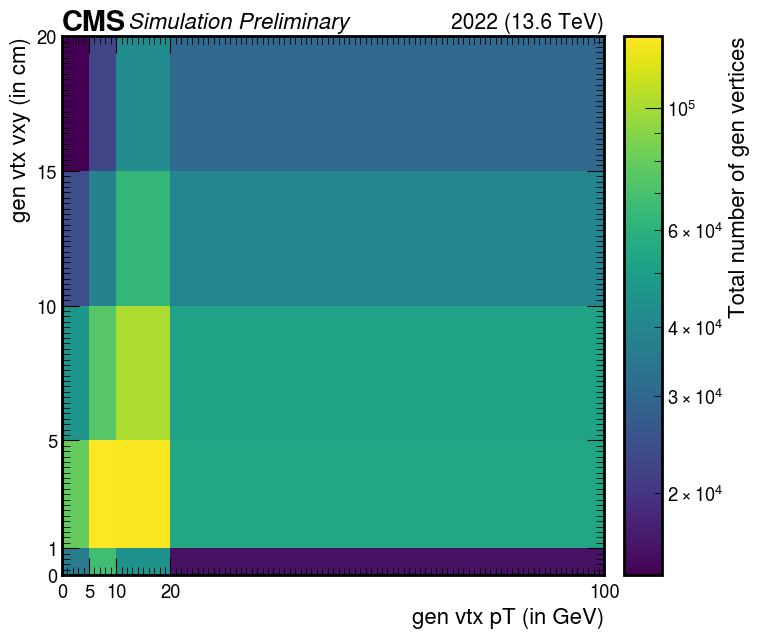

In [4]:
fig, ax = plt.subplots(figsize=(7,7))


# Plot settings
plot_dict = {
    'variable':'genvtx_pt_vxy_den',
    'cut': 'cut0',
    'year': 2022
}

style_2d_dict = {
    'fig': fig,
    'ax': ax,
    'xrebin': None,
    'yrebin': None,
    'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]  
    'ylim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': False, 
    'doLogx': False,
    'doLogz': True,
    'xlabel': "gen vtx pT (in GeV)",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
    'ylabel': "gen vtx vxy (in cm)",   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'zlabel': "Total number of gen vertices",   
    'flow': None,     # overflow
    'doSave': False,
    'outDir': './plots/signal_2018',
    'outName': f'ptvslxy.png'
}

#signal points
samples = {
    # 10: 
    # {
        
    #     0.2: [100],
    # },
    # 20: 
    # {
        
    #     0.2: [100],
        
    # },
    # 30: 
    # {
       
    #     0.2: [100]
    # },
    # 40: 
    # {
    #     0.2: [100],
    # },
    50:
    {
        
        0.2: [100],
    },
    # 60:
    # {
        
    #      0.1: [100],
    #      0.2: [100]
    
    # },
    # 70:
    # {    0.1: [100],
    #      0.2: [100],
    # },
    # 80:
    # {    0.1: [100],
    #      0.2: [100],
    # },
    # 90:
    # {    0.1: [100],
    #      0.2: [100],
    # },
    # 100:
    # {   
    #      0.2: [100],
    # }
}


h_list_lpt_den=[]
h_sum_lpt_den = None

sum_counts_den = None
sum_edges_pt_den = None
sum_edges_vxy_den = None

for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            h_lpt_den = ptools.plot_signal_2D(sig_histo, m1, delta, ctau, plot_dict, style_2d_dict)
            counts_i_den = np.asarray(h_lpt_den[0], dtype=float) 
            edges_pt_den = np.asarray(h_lpt_den[1], dtype=float)
            edges_vxy_den = np.asarray(h_lpt_den[2], dtype=float)
            h_list_lpt_den.append((counts_i_den, edges_pt_den, edges_vxy_den))
            if sum_counts_den is None: 
                sum_counts_den = counts_i_den.copy() 
                sum_edges_pt_den = edges_pt_den.copy() 
                sum_edges_vxy_den = edges_vxy_den.copy()
            else: 
                sum_counts_den += counts_i_den
            
print ("sum_counts_den=", sum_counts_den)
print ("sum_edges_pt_den=", sum_edges_pt_den)
print ("sum_edges_vxy_den=", sum_edges_vxy_den)


In [5]:
# import numpy as np

# # VTX_Res_LL_NOCUTS.ipynb
# sum_counts_LL = np.array([
#     [10142,  7034,   721,    99,    19],
#     [27659, 30929,  6792,  1555,   429],
#     [35446, 69214, 33932, 12435,  5388],
#     [25637, 64124, 54477, 28336, 15926]
# ], dtype=float)

# # VTX_Res_RR_NOCUTS.ipynb
# sum_counts_RR = np.array([
#     [ 4764,  1090,   24,  1,  0],
#     [21751,  6261,  161,  4,  2],
#     [62552, 34600, 1663, 35,  9],
#     [49739, 48725, 3668, 74, 12]
# ], dtype=float)

# # VTX_Res_LR_NOCUTS.ipynb
# sum_counts_LR = np.array([
#     [ 6183,  2407,    89,    8,   2],
#     [25190, 14273,   943,   75,  21],
#     [40428, 43476,  6369,  606, 172],
#     [21560, 44248, 10372, 1003, 341]
# ], dtype=float)

# # Rows: pT bins; columns: vxy bins
# sum_edges_pt = np.array([0, 5, 10, 20, 100], dtype=float)
# sum_edges_vxy = np.array([0, 1, 5, 10, 15, 20], dtype=float)

# # Bin-by-bin total
# sum_counts_total = sum_counts_LL + sum_counts_RR + sum_counts_LR

# print("sum_counts_total =\n", sum_counts_total)

# # Totals across all bins
# print("LL total:", sum_counts_LL.sum())
# print("RR total:", sum_counts_RR.sum())
# print("LR total:", sum_counts_LR.sum())
# print("Overall total:", sum_counts_total.sum())

In [6]:
import numpy as np

# VTX_Res_LL_NOCUTS (1).ipynb
sum_counts_LL = np.array([
    [1005,  638,   52,   10,    0],
    [2659, 2253,  287,   52,    6],
    [2534, 5522, 2864,  983,  379],
    [2152, 5108, 4760, 2737, 1559]
], dtype=float)

# VTX_Res_RR_NOCUTS (1).ipynb
sum_counts_RR = np.array([
    [ 434,   80,   3, 0, 0],
    [1959,  448,   1, 0, 0],
    [4872, 3217, 119, 2, 0],
    [3205, 4263, 375, 7, 1]
], dtype=float)

# VTX_Res_LR_NOCUTS (1).ipynb
sum_counts_LR = np.array([
    [ 624,  191,   7,   1,  0],
    [2522,  986,  47,   3,  0],
    [3123, 3899, 533,  44, 14],
    [1413, 3542, 904, 112, 37]
], dtype=float)

# Rows: pT bins; columns: vxy bins
sum_edges_pt = np.array([0, 5, 10, 20, 100], dtype=float)
sum_edges_vxy = np.array([0, 1, 5, 10, 15, 20], dtype=float)

# Bin-by-bin total
sum_counts_total = sum_counts_LL + sum_counts_RR + sum_counts_LR

print("sum_counts_total =\n", sum_counts_total)

# Totals across all bins
print("LL total:", sum_counts_LL.sum())
print("RR total:", sum_counts_RR.sum())
print("LR total:", sum_counts_LR.sum())
print("Overall total:", sum_counts_total.sum())

sum_counts_total =
 [[2.0630e+03 9.0900e+02 6.2000e+01 1.1000e+01 0.0000e+00]
 [7.1400e+03 3.6870e+03 3.3500e+02 5.5000e+01 6.0000e+00]
 [1.0529e+04 1.2638e+04 3.5160e+03 1.0290e+03 3.9300e+02]
 [6.7700e+03 1.2913e+04 6.0390e+03 2.8560e+03 1.5970e+03]]
LL total: 35560.0
RR total: 18986.0
LR total: 18002.0
Overall total: 72548.0


In [7]:
def eff_determine_unc(n, d):
    eff = np.divide(n, d)
    unc = hist.intervals.ratio_uncertainty(n, d, 'efficiency')
    return eff, unc


efficiency_lpt, unc_lpt = eff_determine_unc(sum_counts_total, sum_counts_den)
print ("efficiency_lpt=", efficiency_lpt)
print ("unc_lpt=", unc_lpt)

efficiency_lpt= [[5.69040658e-02 1.14756789e-02 1.34164286e-03 4.55109640e-04
  0.00000000e+00]
 [1.05730786e-01 2.73384496e-02 4.50984088e-03 1.42998284e-03
  2.65533723e-04]
 [2.38234229e-01 9.60407326e-02 3.44604528e-02 1.61901915e-02
  9.39674342e-03]
 [4.32146049e-01 2.37314612e-01 1.15140422e-01 7.20920840e-02
  5.33400134e-02]]
unc_lpt= [[[0.00121812 0.00037851 0.00016984 0.00013509 0.        ]
  [0.00118481 0.00044422 0.00024578 0.00019213 0.00010532]
  [0.00203172 0.00081297 0.00057137 0.00050078 0.00047179]
  [0.00398523 0.00182815 0.00139589 0.00130118 0.00130029]]

 [[0.00124284 0.00039105 0.0001928  0.00018267 0.00012994]
  [0.00119656 0.00045128 0.00025949 0.00021981 0.00015856]
  [0.00204363 0.00081914 0.00058057 0.00051624 0.00049584]
  [0.00399396 0.00183786 0.00141066 0.00132299 0.00133051]]]


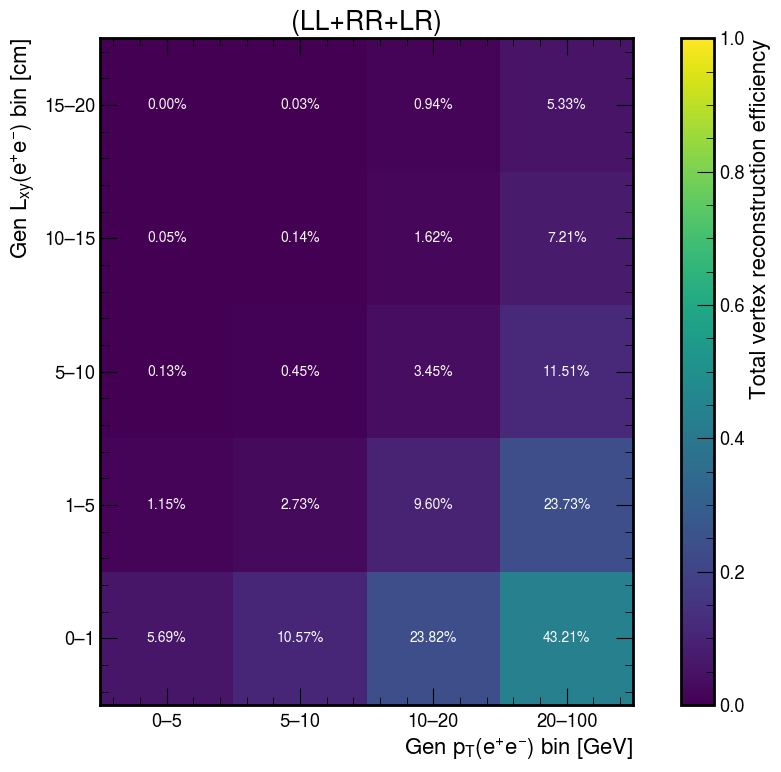

In [8]:
# Calculate the 2D efficiency safely
efficiency_lpt = np.divide(
    sum_counts_total,
    sum_counts_den,
    out=np.full_like(sum_counts_total, np.nan, dtype=float),
    where=(sum_counts_den > 0)
)

# Rows: vxy bins; columns: pT bins
efficiency_to_plot = efficiency_lpt.T

n_vxy, n_pt = efficiency_to_plot.shape

# Equally spaced positions: every bin has the same visual size
pt_positions = np.arange(n_pt + 1)
vxy_positions = np.arange(n_vxy + 1)

pt_centers = np.arange(n_pt) + 0.5
vxy_centers = np.arange(n_vxy) + 0.5

fig, ax = plt.subplots(figsize=(10, 8))

mesh = ax.pcolormesh(
    pt_positions,
    vxy_positions,
    efficiency_to_plot,
    cmap="viridis",
    shading="flat",
    vmin=0,
    vmax=1
)

# Make every bin appear as a square
ax.set_aspect("equal")

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("Total vertex reconstruction efficiency")

# Write the efficiency percentage inside each square
for vxy_index, vxy_center in enumerate(vxy_centers):
    for pt_index, pt_center in enumerate(pt_centers):

        efficiency = efficiency_to_plot[vxy_index, pt_index]

        # Leave bins with no denominator events blank
        if np.isnan(efficiency):
            continue

        text_color = "white" if efficiency < 0.5 else "black"

        ax.text(
            pt_center,
            vxy_center,
            f"{100 * efficiency:.2f}%",
            ha="center",
            va="center",
            color=text_color,
            fontsize=10
        )

# Labels show the actual bin ranges
x_labels = [
    f"{low:g}–{high:g}"
    for low, high in zip(sum_edges_pt[:-1], sum_edges_pt[1:])
]

y_labels = [
    f"{low:g}–{high:g}"
    for low, high in zip(sum_edges_vxy[:-1], sum_edges_vxy[1:])
]

ax.set_xticks(pt_centers)
ax.set_xticklabels(x_labels)

ax.set_yticks(vxy_centers)
ax.set_yticklabels(y_labels)

ax.set_xlabel(r"Gen $p_{\mathrm{T}}(e^{+}e^{-})$ bin [GeV]")
ax.set_ylabel(r"Gen $L_{xy}(e^{+}e^{-})$ bin [cm]")


ax.set_title(
    "(LL+RR+LR)"
    
)
plt.tight_layout()
plt.show()